
# Daily Retail Revenue Prediction

## Project Objective
This project uses historical retail transaction data to develop a machine learning model that predicts daily retail revenue.

## Problem Statement
Small business owners need to make informed decisions about stock, sales targets, and daily business planning. Predicting expected daily revenue can help them plan their activities.

## Dataset
We use the Online Retail II dataset, which contains historical retail transactions from December 2009 to December 2011.

## Prediction Target
Our target variable is daily net revenue in British pounds (£).

## Modelling Approach
We will explore and clean the dataset, create useful features, train four regression models, compare their performance, and save the best model.


from pathlib import Path

# Locate the Excel dataset
file_path = Path("data/raw/online_retail_II.xlsx")

# Read both sheets from the Excel file
sheets = pd.read_excel(file_path, sheet_name=None)

# Combine the sheets into one DataFrame
df = pd.concat(sheets.values(), ignore_index=True)

print("DATASET SHAPE:")
print(df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nFIRST FIVE ROWS:")
display(df.head())

print("\nNUMERICAL SUMMARY:")
display(df.describe())

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("Notebook is working correctly!")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

Notebook is working correctly!
Pandas version: 3.1.1
Scikit-learn version: 1.9.1


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("All imports successful!")

All imports successful!


In [5]:
from pathlib import Path

# Locate the Excel dataset
file_path = Path("data/raw/online_retail_II.xlsx")

# Read both Excel sheets
sheets = pd.read_excel(file_path, sheet_name=None)

# Combine both sheets
df = pd.concat(sheets.values(), ignore_index=True)

print("DATASET SHAPE:")
print(df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nFIRST FIVE ROWS:")
display(df.head())

print("\nNUMERICAL SUMMARY:")
display(df.describe())

DATASET SHAPE:
(1067371, 8)

COLUMN NAMES:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

DATA TYPES:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

FIRST FIVE ROWS:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



NUMERICAL SUMMARY:


,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [6]:

# Check missing values
print("MISSING VALUES:")
display(df.isnull().sum())

# Convert invoice numbers to strings
invoice_numbers = df["Invoice"].astype(str)

# Count cancelled invoices
cancelled = invoice_numbers.str.startswith("C")

print("\nCANCELLED INVOICE ROWS:")
print(cancelled.sum())

# Count negative quantities
print("\nNEGATIVE QUANTITY ROWS:")
print((df["Quantity"] < 0).sum())

# Count zero or negative prices
print("\nZERO OR NEGATIVE PRICE ROWS:")
print((df["Price"] <= 0).sum())

# Count unique countries
print("\nUNIQUE COUNTRIES:")
print(df["Country"].nunique())


MISSING VALUES:


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


CANCELLED INVOICE ROWS:
19494

NEGATIVE QUANTITY ROWS:
22950

ZERO OR NEGATIVE PRICE ROWS:
6207

UNIQUE COUNTRIES:
43


In [7]:

# Make a copy so we preserve the original dataset
clean_df = df.copy()

# Convert invoice numbers to strings
clean_df["Invoice"] = clean_df["Invoice"].astype(str)

# Identify cancelled invoices
cancelled_mask = clean_df["Invoice"].str.startswith("C")

# Identify invalid prices
invalid_price_mask = clean_df["Price"] <= 0

# Keep non-cancelled invoices with positive prices
valid_mask = (~cancelled_mask) & (~invalid_price_mask)

clean_df = clean_df.loc[valid_mask].copy()

# Calculate revenue for each transaction line
# Negative quantities are retained because they can represent returns
clean_df["Revenue"] = clean_df["Quantity"] * clean_df["Price"]

# Extract the calendar date from the invoice timestamp
clean_df["Date"] = clean_df["InvoiceDate"].dt.normalize()

print("ORIGINAL ROWS:", len(df))
print("CLEANED ROWS:", len(clean_df))
print("REMOVED ROWS:", len(df) - len(clean_df))

print("\nREMAINING NEGATIVE QUANTITY ROWS:")
print((clean_df["Quantity"] < 0).sum())

print("\nREMAINING NEGATIVE REVENUE ROWS:")
print((clean_df["Revenue"] < 0).sum())

print("\nCLEANED DATA SAMPLE:")
display(clean_df[["Invoice", "InvoiceDate", "Country",
                  "Quantity", "Price", "Revenue", "Date"]].head())


ORIGINAL ROWS: 1067371
CLEANED ROWS: 1041670
REMOVED ROWS: 25701

REMAINING NEGATIVE QUANTITY ROWS:
0

REMAINING NEGATIVE REVENUE ROWS:
0

CLEANED DATA SAMPLE:


,Invoice,InvoiceDate,Country,Quantity,Price,Revenue,Date
0,489434,2009-12-01 07:45:00,United Kingdom,12,6.95,83.4,2009-12-01
1,489434,2009-12-01 07:45:00,United Kingdom,12,6.75,81.0,2009-12-01
2,489434,2009-12-01 07:45:00,United Kingdom,12,6.75,81.0,2009-12-01
3,489434,2009-12-01 07:45:00,United Kingdom,48,2.10,100.8,2009-12-01
4,489434,2009-12-01 07:45:00,United Kingdom,24,1.25,30.0,2009-12-01


In [8]:
# Identify the original negative-quantity rows
negative_quantity = df["Quantity"] < 0

# Check why these rows were removed
print("TOTAL NEGATIVE QUANTITY ROWS:")
print(negative_quantity.sum())

print("\nNEGATIVE QUANTITY ROWS WITH CANCELLED INVOICES:")
print((negative_quantity & cancelled_mask).sum())

print("\nNEGATIVE QUANTITY ROWS WITH INVALID PRICES:")
print((negative_quantity & invalid_price_mask).sum())

print("\nNEGATIVE QUANTITY ROWS THAT PASSED BOTH FILTERS:")
print((negative_quantity & valid_mask).sum())

print("\nEXAMPLES OF NEGATIVE QUANTITY ROWS:")
display(
    df.loc[negative_quantity, [
        "Invoice", "Quantity", "Price", "InvoiceDate", "Country"
    ]].head(10)
)

TOTAL NEGATIVE QUANTITY ROWS:
22950

NEGATIVE QUANTITY ROWS WITH CANCELLED INVOICES:
19493

NEGATIVE QUANTITY ROWS WITH INVALID PRICES:
3457

NEGATIVE QUANTITY ROWS THAT PASSED BOTH FILTERS:
0

EXAMPLES OF NEGATIVE QUANTITY ROWS:


,Invoice,Quantity,Price,InvoiceDate,Country
178,C489449,-12,2.95,2009-12-01 10:33:00,Australia
179,C489449,-6,1.65,2009-12-01 10:33:00,Australia
180,C489449,-4,4.25,2009-12-01 10:33:00,Australia
181,C489449,-6,2.10,2009-12-01 10:33:00,Australia
182,C489449,-12,2.95,2009-12-01 10:33:00,Australia
183,C489449,-12,1.25,2009-12-01 10:33:00,Australia
184,C489449,-12,1.25,2009-12-01 10:33:00,Australia
185,C489449,-24,0.85,2009-12-01 10:33:00,Australia
186,C489449,-12,2.95,2009-12-01 10:33:00,Australia
196,C489459,-3,4.25,2009-12-01 10:44:00,United Kingdom


In [9]:

# Group transactions by country and date
daily_df = (
    clean_df
    .groupby(["Country", "Date"], as_index=False)
    .agg(
        DailyRevenue=("Revenue", "sum"),
        TransactionLines=("Invoice", "size")
    )
)

# Display the results
print("DAILY DATASET SHAPE:")
print(daily_df.shape)

print("\nNUMBER OF COUNTRIES:")
print(daily_df["Country"].nunique())

print("\nDATE RANGE:")
print(daily_df["Date"].min(), "to", daily_df["Date"].max())

print("\nFIRST TEN DAILY RECORDS:")
display(daily_df.head(10))

print("\nDAILY REVENUE SUMMARY:")
display(daily_df["DailyRevenue"].describe())


DAILY DATASET SHAPE:
(2893, 4)

NUMBER OF COUNTRIES:
43

DATE RANGE:
2009-12-01 00:00:00 to 2011-12-09 00:00:00

FIRST TEN DAILY RECORDS:


,Country,Date,DailyRevenue,TransactionLines
0,Australia,2009-12-01,196.10,9
1,Australia,2009-12-18,75.00,5
2,Australia,2010-02-14,662.25,15
3,Australia,2010-02-21,202.56,11
4,Australia,2010-02-22,164.85,6
5,Australia,2010-03-04,394.59,17
6,Australia,2010-03-23,34.80,2
7,Australia,2010-04-08,396.20,10
8,Australia,2010-04-27,234.75,7
9,Australia,2010-05-06,1520.07,28



DAILY REVENUE SUMMARY:


count      2893.000000
mean       7249.427780
std       14733.819936
min           2.950000
25%         403.830000
50%         954.930000
75%        4400.280000
max      196134.100000
Name: DailyRevenue, dtype: float64

In [10]:

# Store the daily records for each country
country_ranges = daily_df.groupby("Country")["Date"].agg(["min", "max"])

# Create a complete daily calendar for every country
complete_daily_data = []

for country, date_range in country_ranges.iterrows():

    # Generate every date between the country's first and last recorded sale
    all_dates = pd.date_range(
        start=date_range["min"],
        end=date_range["max"],
        freq="D"
    )

    # Select the country's existing daily records
    country_data = (
        daily_df[daily_df["Country"] == country]
        .set_index("Date")
    )

    # Add dates that were missing from the original records
    country_data = country_data.reindex(all_dates)

    # Restore the country name
    country_data["Country"] = country

    # Days without transactions have zero revenue and zero transaction lines
    country_data["DailyRevenue"] = country_data["DailyRevenue"].fillna(0)
    country_data["TransactionLines"] = (
        country_data["TransactionLines"].fillna(0)
    )

    # Restore the date column
    country_data.index.name = "Date"
    country_data = country_data.reset_index()

    complete_daily_data.append(country_data)

# Combine all countries into one complete dataset
full_daily_df = pd.concat(complete_daily_data, ignore_index=True)

# Sort by country and date
full_daily_df = full_daily_df.sort_values(
    ["Country", "Date"]
).reset_index(drop=True)

# Display the results
print("COMPLETE DAILY DATASET SHAPE:")
print(full_daily_df.shape)

print("\nNUMBER OF COUNTRIES:")
print(full_daily_df["Country"].nunique())

print("\nMISSING VALUES:")
print(full_daily_df.isnull().sum())

print("\nFIRST TEN RECORDS:")
display(full_daily_df.head(10))

print("\nNUMBER OF DAYS WITHOUT RECORDED SALES:")
print((full_daily_df["DailyRevenue"] == 0).sum())


COMPLETE DAILY DATASET SHAPE:
(22458, 4)

NUMBER OF COUNTRIES:
43

MISSING VALUES:
Date                0
Country             0
DailyRevenue        0
TransactionLines    0
dtype: int64

FIRST TEN RECORDS:


,Date,Country,DailyRevenue,TransactionLines
0,2009-12-01,Australia,196.1,9.0
1,2009-12-02,Australia,0.0,0.0
2,2009-12-03,Australia,0.0,0.0
3,2009-12-04,Australia,0.0,0.0
4,2009-12-05,Australia,0.0,0.0
5,2009-12-06,Australia,0.0,0.0
6,2009-12-07,Australia,0.0,0.0
7,2009-12-08,Australia,0.0,0.0
8,2009-12-09,Australia,0.0,0.0
9,2009-12-10,Australia,0.0,0.0



NUMBER OF DAYS WITHOUT RECORDED SALES:
19565


In [11]:

# Make a copy of our complete daily dataset
model_df = full_daily_df.copy()

# Sort records by country and date
model_df = model_df.sort_values(
    ["Country", "Date"]
).reset_index(drop=True)

# Create calendar features
model_df["Year"] = model_df["Date"].dt.year
model_df["Month"] = model_df["Date"].dt.month
model_df["Day"] = model_df["Date"].dt.day
model_df["DayOfWeek"] = model_df["Date"].dt.day_of_week

# Identify weekends (Saturday = 5, Sunday = 6)
model_df["IsWeekend"] = (
    model_df["DayOfWeek"].isin([5, 6]).astype(int)
)

# Create historical revenue features for each country
model_df["Lag1Day"] = (
    model_df.groupby("Country")["DailyRevenue"].shift(1)
)

model_df["Lag7Days"] = (
    model_df.groupby("Country")["DailyRevenue"].shift(7)
)

# Calculate rolling averages using previous days only
model_df["Rolling7Days"] = (
    model_df.groupby("Country")["DailyRevenue"]
    .transform(lambda values: values.shift(1).rolling(7).mean())
)

model_df["Rolling30Days"] = (
    model_df.groupby("Country")["DailyRevenue"]
    .transform(lambda values: values.shift(1).rolling(30).mean())
)

# Remove rows without enough historical information
model_df = model_df.dropna().reset_index(drop=True)

# Display the results
print("MODEL DATASET SHAPE:")
print(model_df.shape)

print("\nMODEL FEATURES:")
print(model_df.columns.tolist())

print("\nMISSING VALUES:")
print(model_df.isnull().sum())

print("\nFIRST FIVE RECORDS:")
display(model_df.head())


MODEL DATASET SHAPE:
(21270, 13)

MODEL FEATURES:
['Date', 'Country', 'DailyRevenue', 'TransactionLines', 'Year', 'Month', 'Day', 'DayOfWeek', 'IsWeekend', 'Lag1Day', 'Lag7Days', 'Rolling7Days', 'Rolling30Days']

MISSING VALUES:
Date                0
Country             0
DailyRevenue        0
TransactionLines    0
Year                0
Month               0
Day                 0
DayOfWeek           0
IsWeekend           0
Lag1Day             0
Lag7Days            0
Rolling7Days        0
Rolling30Days       0
dtype: int64

FIRST FIVE RECORDS:


,Date,Country,DailyRevenue,TransactionLines,Year,Month,Day,DayOfWeek,IsWeekend,Lag1Day,Lag7Days,Rolling7Days,Rolling30Days
0,2009-12-31,Australia,0.0,0.0,2009,12,31,3,0,0.0,0.0,0.0,9.036667
1,2010-01-01,Australia,0.0,0.0,2010,1,1,4,0,0.0,0.0,0.0,2.500000
2,2010-01-02,Australia,0.0,0.0,2010,1,2,5,1,0.0,0.0,0.0,2.500000
3,2010-01-03,Australia,0.0,0.0,2010,1,3,6,1,0.0,0.0,0.0,2.500000
4,2010-01-04,Australia,0.0,0.0,2010,1,4,0,0,0.0,0.0,0.0,2.500000


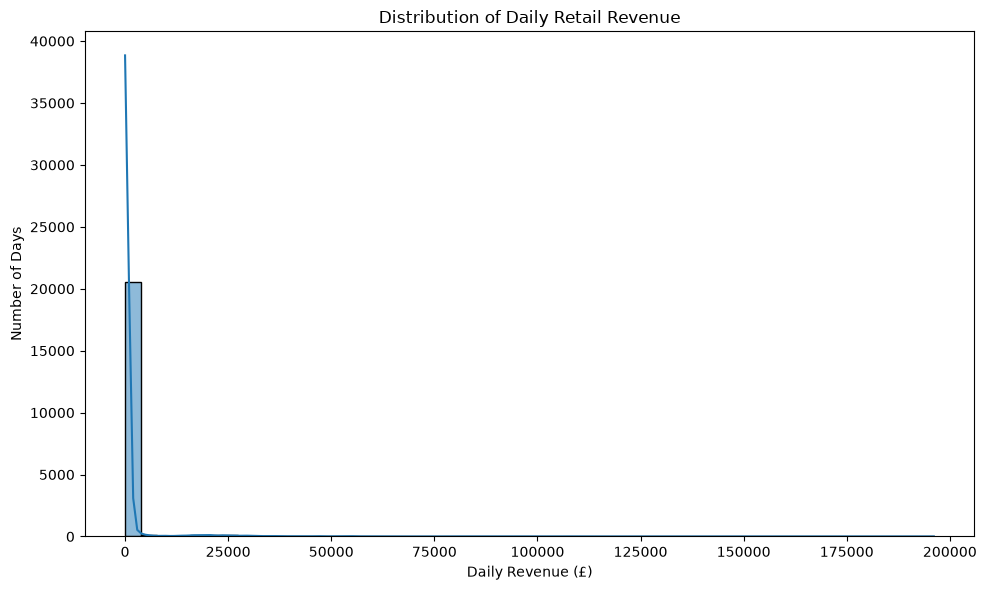

In [12]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=model_df,
    x="DailyRevenue",
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Retail Revenue")
plt.xlabel("Daily Revenue (£)")
plt.ylabel("Number of Days")
plt.tight_layout()
plt.show()


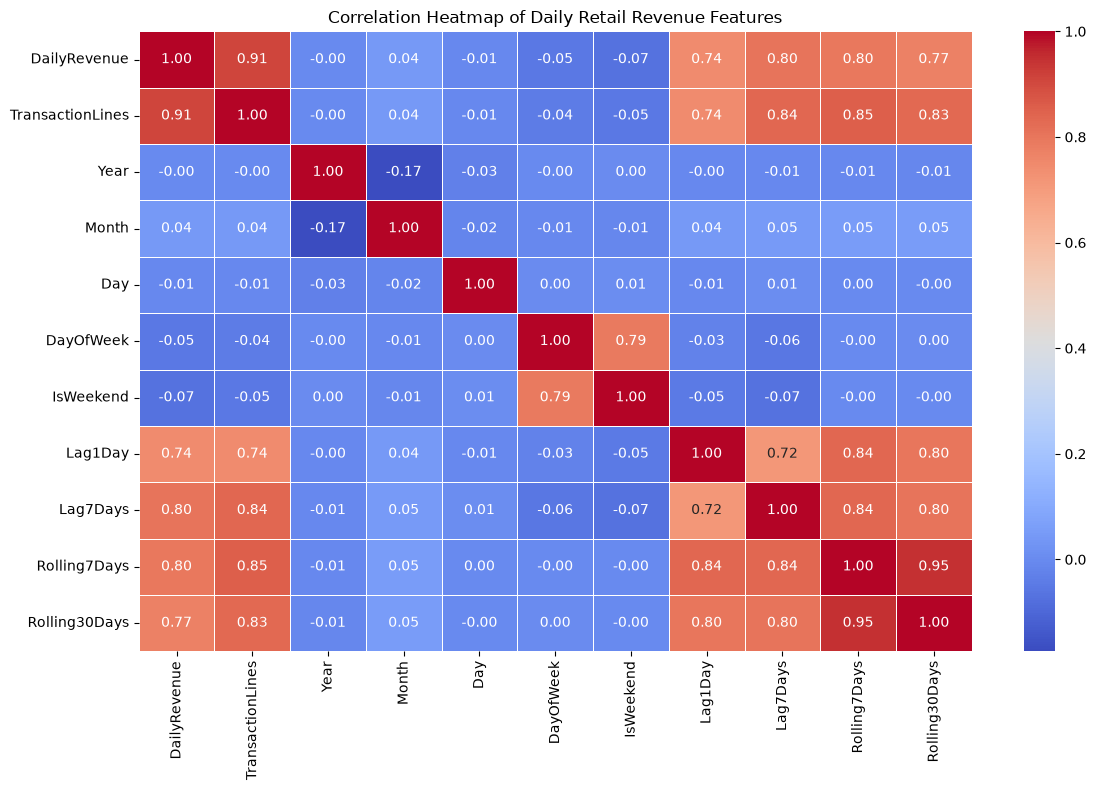

In [13]:

# Select numerical columns for correlation analysis
numeric_df = model_df.select_dtypes(include=["number"])

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Display the correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Daily Retail Revenue Features")
plt.tight_layout()
plt.show()


### Visualization 2: Correlation Heatmap

The correlation heatmap shows the relationships between the numerical features in our dataset. It helps us identify which historical revenue features have stronger relationships with daily revenue. These relationships can guide our feature selection, although correlation does not necessarily mean causation.

In [14]:

# Select the input features
feature_columns = [
    "Country",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "IsWeekend",
    "Lag1Day",
    "Lag7Days",
    "Rolling7Days",
    "Rolling30Days"
]

# Create input features and target
X = model_df[feature_columns]
y = model_df["DailyRevenue"]

# Display dataset information
print("INPUT FEATURES SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

print("\nINPUT FEATURES:")
print(X.columns.tolist())

print("\nTARGET VARIABLE:")
print(y.name)

print("\nFIRST FIVE INPUT RECORDS:")
display(X.head())

print("\nFIRST FIVE TARGET VALUES:")
display(y.head())


INPUT FEATURES SHAPE: (21270, 10)
TARGET SHAPE: (21270,)

INPUT FEATURES:
['Country', 'Year', 'Month', 'Day', 'DayOfWeek', 'IsWeekend', 'Lag1Day', 'Lag7Days', 'Rolling7Days', 'Rolling30Days']

TARGET VARIABLE:
DailyRevenue

FIRST FIVE INPUT RECORDS:


,Country,Year,Month,Day,DayOfWeek,IsWeekend,Lag1Day,Lag7Days,Rolling7Days,Rolling30Days
0,Australia,2009,12,31,3,0,0.0,0.0,0.0,9.036667
1,Australia,2010,1,1,4,0,0.0,0.0,0.0,2.500000
2,Australia,2010,1,2,5,1,0.0,0.0,0.0,2.500000
3,Australia,2010,1,3,6,1,0.0,0.0,0.0,2.500000
4,Australia,2010,1,4,0,0,0.0,0.0,0.0,2.500000



FIRST FIVE TARGET VALUES:


0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: DailyRevenue, dtype: float64

In [15]:

# Get all unique dates in chronological order
unique_dates = sorted(model_df["Date"].unique())

# Find the date that separates training and testing data
split_position = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_position]

# Split the data chronologically
train_mask = model_df["Date"] < split_date
test_mask = model_df["Date"] >= split_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Display the split information
print("SPLIT DATE:", split_date)

print("\nTRAINING DATA SHAPE:", X_train.shape)
print("TESTING DATA SHAPE:", X_test.shape)

print("\nTRAINING DATE RANGE:")
print(model_df.loc[train_mask, "Date"].min(),
      "to",
      model_df.loc[train_mask, "Date"].max())

print("\nTESTING DATE RANGE:")
print(model_df.loc[test_mask, "Date"].min(),
      "to",
      model_df.loc[test_mask, "Date"].max())

print("\nTRAINING TARGET SHAPE:", y_train.shape)
print("TESTING TARGET SHAPE:", y_test.shape)


SPLIT DATE: 2011-07-21 00:00:00

TRAINING DATA SHAPE: (17337, 10)
TESTING DATA SHAPE: (3933, 10)

TRAINING DATE RANGE:
2009-12-31 00:00:00 to 2011-07-20 00:00:00

TESTING DATE RANGE:
2011-07-21 00:00:00 to 2011-12-09 00:00:00

TRAINING TARGET SHAPE: (17337,)
TESTING TARGET SHAPE: (3933,)


In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate categorical and numerical features
categorical_features = ["Country"]

numerical_features = [
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "IsWeekend",
    "Lag1Day",
    "Lag7Days",
    "Rolling7Days",
    "Rolling30Days"
]

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "country",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numbers",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

# Display the results
print("ORIGINAL TRAINING SHAPE:", X_train.shape)
print("PROCESSED TRAINING SHAPE:", X_train_processed.shape)

print("\nORIGINAL TESTING SHAPE:", X_test.shape)
print("PROCESSED TESTING SHAPE:", X_test_processed.shape)

print("\nCOUNTRY CATEGORIES:")
print(preprocessor.named_transformers_["country"].categories_)


ORIGINAL TRAINING SHAPE: (17337, 10)
PROCESSED TRAINING SHAPE: (17337, 48)

ORIGINAL TESTING SHAPE: (3933, 10)
PROCESSED TESTING SHAPE: (3933, 48)

COUNTRY CATEGORIES:
[array(['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brazil', 'Canada',
       'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'EIRE',
       'European Community', 'Finland', 'France', 'Germany', 'Greece',
       'Hong Kong', 'Iceland', 'Israel', 'Italy', 'Japan', 'Korea',
       'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Nigeria',
       'Norway', 'Poland', 'Portugal', 'RSA', 'Singapore', 'Spain',
       'Sweden', 'Switzerland', 'USA', 'United Arab Emirates',
       'United Kingdom', 'Unspecified'], dtype=object)]


In [17]:

from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# Create the SGD regression model
sgd_model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=0.0001,
    learning_rate="constant",
    eta0=0.001,
    max_iter=1,
    tol=None,
    random_state=42
)

# Store training and testing losses
train_losses = []
test_losses = []

# Number of training epochs
epochs = 50

# Train one epoch at a time
for epoch in range(epochs):

    sgd_model.partial_fit(X_train_processed, y_train)

    # Predict training and testing data
    train_predictions = sgd_model.predict(X_train_processed)
    test_predictions = sgd_model.predict(X_test_processed)

    # Calculate Mean Squared Error
    train_mse = mean_squared_error(y_train, train_predictions)
    test_mse = mean_squared_error(y_test, test_predictions)

    train_losses.append(train_mse)
    test_losses.append(test_mse)

    print(
        f"Epoch {epoch + 1}: "
        f"Training MSE = {train_mse:.2f}, "
        f"Testing MSE = {test_mse:.2f}"
    )


Epoch 1: Training MSE = 12442610.70, Testing MSE = 28036314.42
Epoch 2: Training MSE = 12212216.33, Testing MSE = 27714238.78
Epoch 3: Training MSE = 11978056.47, Testing MSE = 27309917.22
Epoch 4: Training MSE = 11786328.89, Testing MSE = 26980328.32
Epoch 5: Training MSE = 11618628.27, Testing MSE = 26693628.27
Epoch 6: Training MSE = 11468724.35, Testing MSE = 26437111.02
Epoch 7: Training MSE = 11333994.24, Testing MSE = 26205349.04
Epoch 8: Training MSE = 11212713.50, Testing MSE = 25995176.64
Epoch 9: Training MSE = 11103434.42, Testing MSE = 25804235.23
Epoch 10: Training MSE = 11004864.21, Testing MSE = 25630549.87
Epoch 11: Training MSE = 10915845.01, Testing MSE = 25472395.47
Epoch 12: Training MSE = 10835347.10, Testing MSE = 25328244.66
Epoch 13: Training MSE = 10762459.62, Testing MSE = 25196738.99
Epoch 14: Training MSE = 10696379.01, Testing MSE = 25076667.70
Epoch 15: Training MSE = 10636396.59, Testing MSE = 24966949.83
Epoch 16: Training MSE = 10581886.90, Testing MSE

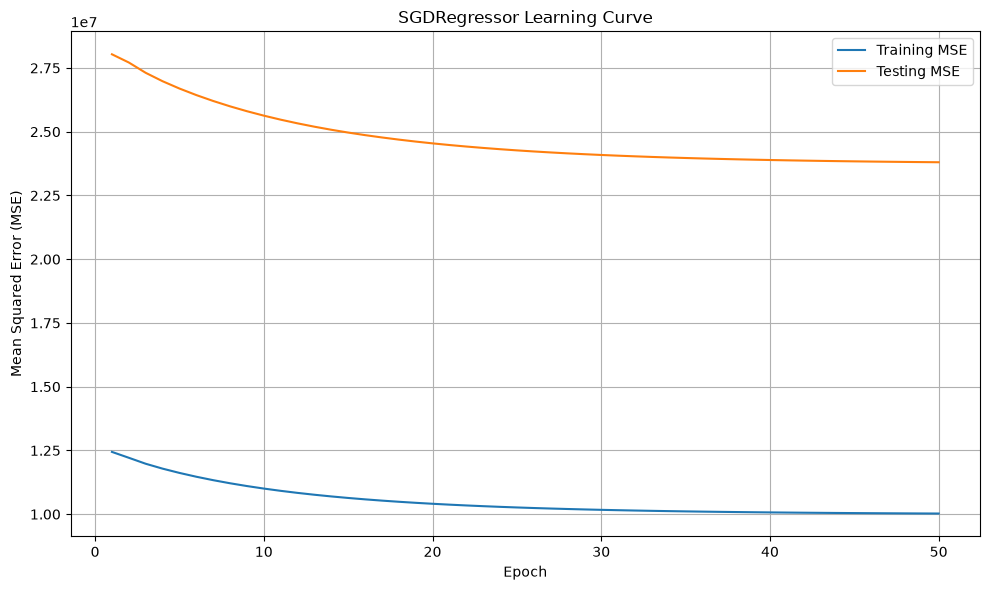

FINAL TRAINING MSE: 10025529.277448285
FINAL TESTING MSE: 23802594.42620913


In [18]:

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training MSE"
)

plt.plot(
    range(1, epochs + 1),
    test_losses,
    label="Testing MSE"
)

plt.title("SGDRegressor Learning Curve")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("FINAL TRAINING MSE:", train_losses[-1])
print("FINAL TESTING MSE:", test_losses[-1])


In [19]:

print("SGD MODEL RESULTS")
print("------------------")
print("Number of epochs:", epochs)
print("Final training MSE:", round(train_losses[-1], 2))
print("Final testing MSE:", round(test_losses[-1], 2))
print("Final training RMSE:", round(np.sqrt(train_losses[-1]), 2))
print("Final testing RMSE:", round(np.sqrt(test_losses[-1]), 2))


SGD MODEL RESULTS
------------------
Number of epochs: 50
Final training MSE: 10025529.28
Final testing MSE: 23802594.43
Final training RMSE: 3166.31
Final testing RMSE: 4878.79


In [20]:

from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# Divide the original training data into training and validation periods
training_dates = model_df.loc[X_train.index, "Date"]
unique_training_dates = sorted(training_dates.unique())

validation_start_position = int(len(unique_training_dates) * 0.8)
validation_start_date = unique_training_dates[validation_start_position]

inner_train_mask = training_dates < validation_start_date
validation_mask = training_dates >= validation_start_date

X_inner_train = X_train.loc[inner_train_mask]
X_validation = X_train.loc[validation_mask]

y_inner_train = y_train.loc[inner_train_mask]
y_validation = y_train.loc[validation_mask]

# Fit a fresh preprocessor using only the inner training data
tuning_preprocessor = ColumnTransformer(
    transformers=[
        ("country", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numbers", StandardScaler(), numerical_features)
    ]
)

X_inner_processed = tuning_preprocessor.fit_transform(X_inner_train)
X_validation_processed = tuning_preprocessor.transform(X_validation)

# Hyperparameter combinations to test
learning_rates = [0.0001, 0.001, 0.01]
regularization_values = [0.0001, 0.001, 0.01]

tuning_results = []

# Test each combination
for learning_rate in learning_rates:
    for alpha_value in regularization_values:

        model = SGDRegressor(
            loss="squared_error",
            penalty="l2",
            alpha=alpha_value,
            learning_rate="constant",
            eta0=learning_rate,
            max_iter=1,
            tol=None,
            random_state=42
        )

        best_validation_mse = float("inf")
        best_epoch = 0

        for epoch in range(1, 51):

            model.partial_fit(X_inner_processed, y_inner_train)

            validation_predictions = model.predict(
                X_validation_processed
            )

            validation_mse = mean_squared_error(
                y_validation,
                validation_predictions
            )

            if validation_mse < best_validation_mse:
                best_validation_mse = validation_mse
                best_epoch = epoch

        tuning_results.append({
            "LearningRate": learning_rate,
            "Alpha": alpha_value,
            "BestEpoch": best_epoch,
            "ValidationMSE": best_validation_mse
        })

# Display and sort tuning results
tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values(
    "ValidationMSE"
).reset_index(drop=True)

print("SGD HYPERPARAMETER TUNING RESULTS:")
display(tuning_df)

print("\nBEST HYPERPARAMETERS:")
display(tuning_df.head(1))


SGD HYPERPARAMETER TUNING RESULTS:


,LearningRate,Alpha,BestEpoch,ValidationMSE
0,0.0001,0.0001,50,4.763150e+06
1,0.0001,0.0010,50,4.764487e+06
2,0.0001,0.0100,50,4.785401e+06
3,0.0010,0.0100,50,5.604802e+06
4,0.0010,0.0010,5,5.648587e+06
5,0.0010,0.0001,5,5.649618e+06
6,0.0100,0.0100,50,1.821852e+07
7,0.0100,0.0010,50,2.113912e+07
8,0.0100,0.0001,50,2.145130e+07



BEST HYPERPARAMETERS:


,LearningRate,Alpha,BestEpoch,ValidationMSE
0,0.0001,0.0001,50,4.763150e+06


In [21]:

# Create the final tuned SGD model
best_sgd_model = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=0.0001,
    learning_rate="constant",
    eta0=0.0001,
    max_iter=1,
    tol=None,
    random_state=42
)

# Store the final model's learning curves
best_sgd_train_losses = []
best_sgd_test_losses = []

# Train for 50 epochs
for epoch in range(50):

    best_sgd_model.partial_fit(X_train_processed, y_train)

    train_predictions = best_sgd_model.predict(X_train_processed)
    test_predictions = best_sgd_model.predict(X_test_processed)

    train_mse = mean_squared_error(y_train, train_predictions)
    test_mse = mean_squared_error(y_test, test_predictions)

    best_sgd_train_losses.append(train_mse)
    best_sgd_test_losses.append(test_mse)

# Display final performance
print("FINAL TUNED SGD MODEL")
print("---------------------")
print("Training MSE:", round(best_sgd_train_losses[-1], 2))
print("Testing MSE:", round(best_sgd_test_losses[-1], 2))
print("Training RMSE:", round(np.sqrt(best_sgd_train_losses[-1]), 2))
print("Testing RMSE:", round(np.sqrt(best_sgd_test_losses[-1]), 2))


FINAL TUNED SGD MODEL
---------------------
Training MSE: 8319524.21
Testing MSE: 17890738.97
Training RMSE: 2884.36
Testing RMSE: 4229.74


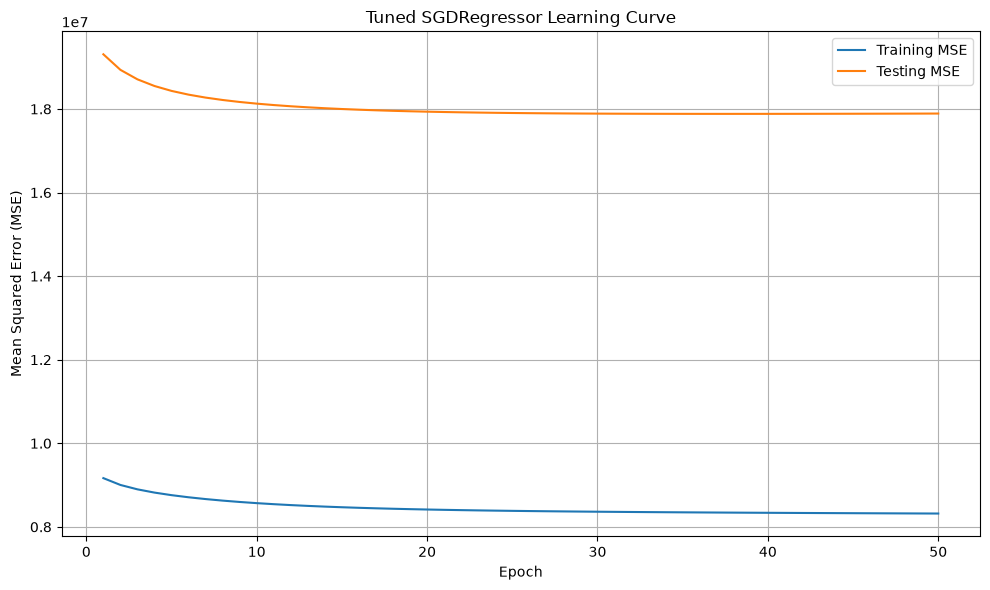

In [22]:

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 51),
    best_sgd_train_losses,
    label="Training MSE"
)

plt.plot(
    range(1, 51),
    best_sgd_test_losses,
    label="Testing MSE"
)

plt.title("Tuned SGDRegressor Learning Curve")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [23]:

print("TUNED SGD MODEL RESULTS")
print("------------------------")
print("Training MSE:", round(best_sgd_train_losses[-1], 2))
print("Testing MSE:", round(best_sgd_test_losses[-1], 2))
print("Training RMSE:", round(np.sqrt(best_sgd_train_losses[-1]), 2))
print("Testing RMSE:", round(np.sqrt(best_sgd_test_losses[-1]), 2))

print("\nCOMPARISON WITH INITIAL SGD MODEL")
print("Initial testing MSE:", round(test_losses[-1], 2))
print("Tuned testing MSE:", round(best_sgd_test_losses[-1], 2))


TUNED SGD MODEL RESULTS
------------------------
Training MSE: 8319524.21
Testing MSE: 17890738.97
Training RMSE: 2884.36
Testing RMSE: 4229.74

COMPARISON WITH INITIAL SGD MODEL
Initial testing MSE: 23802594.43
Tuned testing MSE: 17890738.97


In [24]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_processed, y_train)

# Make predictions
linear_train_predictions = linear_model.predict(X_train_processed)
linear_test_predictions = linear_model.predict(X_test_processed)

# Calculate Mean Squared Error
linear_train_mse = mean_squared_error(
    y_train, linear_train_predictions
)

linear_test_mse = mean_squared_error(
    y_test, linear_test_predictions
)

# Display model performance
print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("Training MSE:", round(linear_train_mse, 2))
print("Testing MSE:", round(linear_test_mse, 2))
print("Training RMSE:", round(np.sqrt(linear_train_mse), 2))
print("Testing RMSE:", round(np.sqrt(linear_test_mse), 2))


LINEAR REGRESSION RESULTS
-------------------------
Training MSE: 8055249.45
Testing MSE: 16948595.6
Training RMSE: 2838.18
Testing RMSE: 4116.87


In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_processed, y_train)

# Make predictions
linear_train_predictions = linear_model.predict(X_train_processed)
linear_test_predictions = linear_model.predict(X_test_processed)

# Calculate Mean Squared Error
linear_train_mse = mean_squared_error(
    y_train, linear_train_predictions
)

linear_test_mse = mean_squared_error(
    y_test, linear_test_predictions
)

# Calculate Root Mean Squared Error
linear_train_rmse = np.sqrt(linear_train_mse)
linear_test_rmse = np.sqrt(linear_test_mse)

# Display results
print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("Training MSE:", round(linear_train_mse, 2))
print("Testing MSE:", round(linear_test_mse, 2))
print("Training RMSE:", round(linear_train_rmse, 2))
print("Testing RMSE:", round(linear_test_rmse, 2))

LINEAR REGRESSION RESULTS
-------------------------
Training MSE: 8055249.45
Testing MSE: 16948595.6
Training RMSE: 2838.18
Testing RMSE: 4116.87


In [26]:
print(X_train_processed.shape)
print(y_train.shape)
print(X_test_processed.shape)
print(y_test.shape)

(17337, 48)
(17337,)
(3933, 48)
(3933,)


The results of the linear regression model are summarized as follows:

The processed training data was used to train the model Linear Regression. It achieved a training MSE of 8,055,249.45 and a testing MSE of 16,948,595.60. The testing RMSE was 4,116.87.

The findings indicate that the model is reasonable, but the prediction errors of the model are higher when tested with the test data set compared to when it is trained with the training data set. It will be compared with Decision Tree and Random Forest models to find the optimum one.

In [27]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Create the Decision Tree model
tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Train the model
tree_model.fit(X_train_processed, y_train)

# Make predictions
tree_train_predictions = tree_model.predict(X_train_processed)
tree_test_predictions = tree_model.predict(X_test_processed)

# Calculate Mean Squared Error
tree_train_mse = mean_squared_error(
    y_train, tree_train_predictions
)

tree_test_mse = mean_squared_error(
    y_test, tree_test_predictions
)

# Calculate Root Mean Squared Error
tree_train_rmse = np.sqrt(tree_train_mse)
tree_test_rmse = np.sqrt(tree_test_mse)

# Display results
print("DECISION TREE REGRESSION RESULTS")
print("--------------------------------")
print("Training MSE:", round(tree_train_mse, 2))
print("Testing MSE:", round(tree_test_mse, 2))
print("Training RMSE:", round(tree_train_rmse, 2))
print("Testing RMSE:", round(tree_test_rmse, 2))

DECISION TREE REGRESSION RESULTS
--------------------------------
Training MSE: 3309228.5
Testing MSE: 15028707.65
Training RMSE: 1819.13
Testing RMSE: 3876.69


###Decision Tree Regression Model Results

The Decision Tree Regressor was fitted with a maximum depth of 10, minimum sample size to split a node of 10 and minimum sample size at a leaf of 5.

The model achieved a training MSE of 3,309,228.50 and a testing MSE of 15,028,707.65. Its testing RMSE was 3,876.69.

The Decision Tree model had a lower testing error than the previous models. The difference between training and testing errors, however, indicates that the model is likely to be overfitting. Before finalizing our model we'll compare it to the Random Forest Regression.

In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Create the Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train_processed, y_train)

# Make predictions
rf_train_predictions = random_forest_model.predict(X_train_processed)
rf_test_predictions = random_forest_model.predict(X_test_processed)

# Calculate Mean Squared Error
rf_train_mse = mean_squared_error(
    y_train, rf_train_predictions
)

rf_test_mse = mean_squared_error(
    y_test, rf_test_predictions
)

# Calculate Root Mean Squared Error
rf_train_rmse = np.sqrt(rf_train_mse)
rf_test_rmse = np.sqrt(rf_test_mse)

# Display results
print("RANDOM FOREST REGRESSION RESULTS")
print("--------------------------------")
print("Training MSE:", round(rf_train_mse, 2))
print("Testing MSE:", round(rf_test_mse, 2))
print("Training RMSE:", round(rf_train_rmse, 2))
print("Testing RMSE:", round(rf_test_rmse, 2))

RANDOM FOREST REGRESSION RESULTS
--------------------------------
Training MSE: 3463989.73
Testing MSE: 11719939.09
Training RMSE: 1861.18
Testing RMSE: 3423.44


In [29]:
import pandas as pd

# Compare the four required regression models
model_comparison = pd.DataFrame({
    "Model": [
        "SGDRegressor (Tuned)",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Training MSE": [
        8319524.21,
        linear_train_mse,
        tree_train_mse,
        rf_train_mse
    ],
    "Testing MSE": [
        17890738.97,
        linear_test_mse,
        tree_test_mse,
        rf_test_mse
    ]
})

# Sort models by testing MSE
model_comparison = model_comparison.sort_values(
    by="Testing MSE"
).reset_index(drop=True)

print("REGRESSION MODEL COMPARISON")
display(model_comparison)

# Identify the best-performing model
best_model_name = model_comparison.loc[0, "Model"]

print("Best Model:", best_model_name)

REGRESSION MODEL COMPARISON


,Model,Training MSE,Testing MSE
0,Random Forest,3.463990e+06,1.171994e+07
1,Decision Tree,3.309229e+06,1.502871e+07
2,Linear Regression,8.055249e+06,1.694860e+07
3,SGDRegressor (Tuned),8.319524e+06,1.789074e+07


Best Model: Random Forest


### Comparison of the Four Regression Models

Four regression models were trained and tested on the same sets of training and testing data.

The lowest testing MSE was obtained by the Random Forest Regressor with a score of 11,719,939.09 and the lowest testing RMSE was obtained by Random Forest Regressor with a score of 3,423.44. This is because it worked best in predicting revenues on data it had never seen before, as opposed to the other three models.

The Decision Tree also achieved a good performance, but with a higher testing error. Both linear regressor models (Linear Regression and SGDRegressor) had higher testing errors than both tree-based models.

Random Forest is the best performing model we have at the moment based on the testing MSE. We will take this as our top choice for further development of the project.

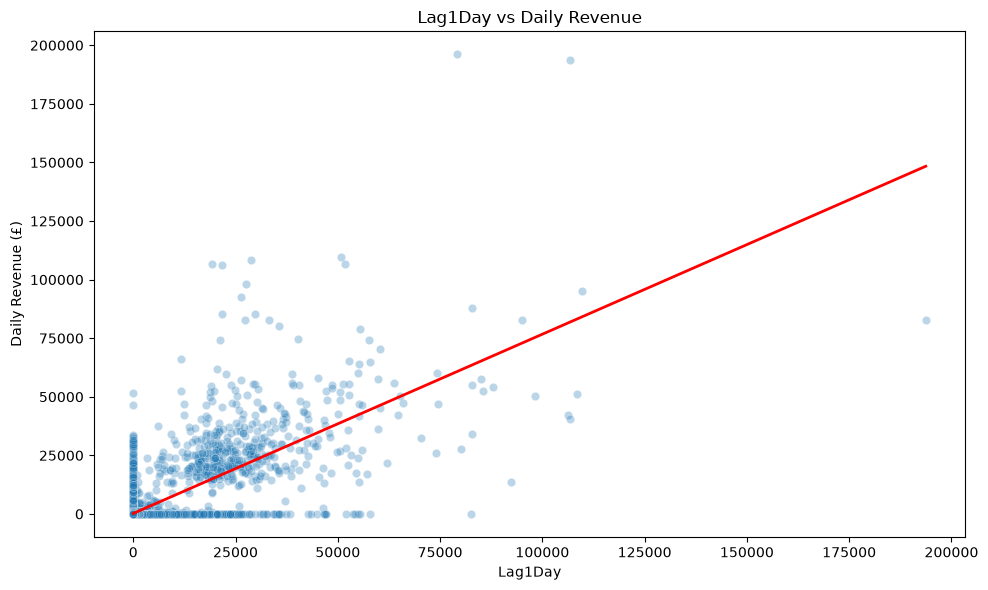

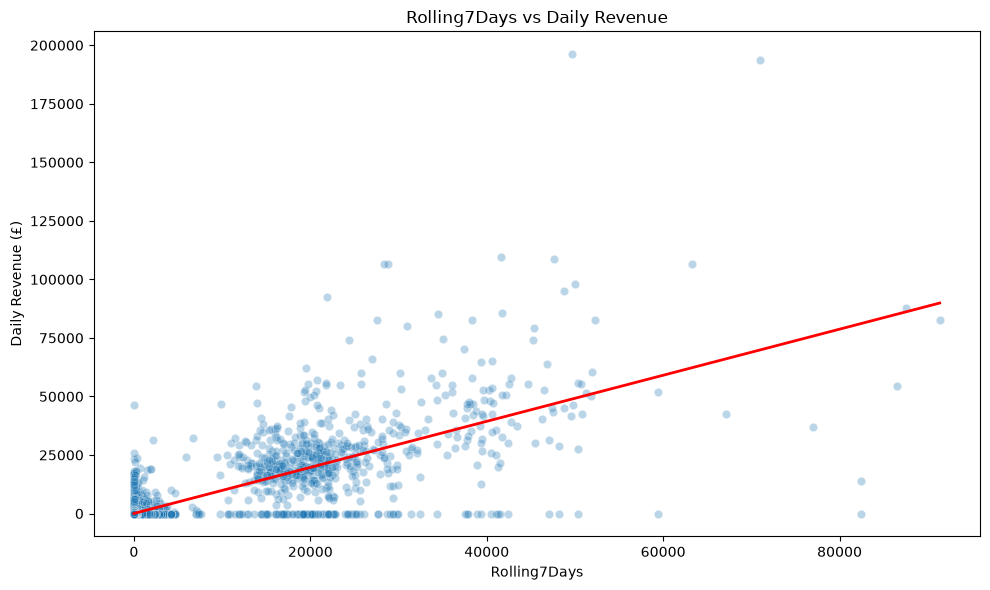

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Select two useful features
features_to_plot = ["Lag1Day", "Rolling7Days"]

for feature in features_to_plot:

    # Get the feature and target values
    X_feature = model_df[[feature]]
    y_target = model_df["DailyRevenue"]

    # Fit a simple linear regression model for visualization
    plot_model = LinearRegression()
    plot_model.fit(X_feature, y_target)

    # Generate predictions for the fitted line
    predicted_line = plot_model.predict(X_feature)

    # Create scatter plot
    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        x=model_df[feature],
        y=y_target,
        alpha=0.3
    )

    # Add fitted regression line
    sorted_indices = X_feature[feature].argsort()

    plt.plot(
        X_feature[feature].iloc[sorted_indices],
        predicted_line[sorted_indices],
        color="red",
        linewidth=2
    )

    plt.title(f"{feature} vs Daily Revenue")
    plt.xlabel(feature)
    plt.ylabel("Daily Revenue (£)")
    plt.tight_layout()
    plt.show()

In [31]:
from pathlib import Path
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# Create a pipeline with preprocessing and Random Forest
best_model_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", clone(random_forest_model))
])

# Train the complete pipeline using the original training data
best_model_pipeline.fit(X_train, y_train)

# Evaluate the saved pipeline on the test data
pipeline_predictions = best_model_pipeline.predict(X_test)

pipeline_test_mse = mean_squared_error(
    y_test,
    pipeline_predictions
)

print("Best Model: Random Forest")
print("Pipeline Testing MSE:", round(pipeline_test_mse, 2))

# Create the API folder if it does not exist
api_folder = Path("../API")
api_folder.mkdir(parents=True, exist_ok=True)

# Save the complete pipeline
model_path = api_folder / "best_model.pkl"

joblib.dump(best_model_pipeline, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())

Best Model: Random Forest
Pipeline Testing MSE: 11719939.09
Model saved successfully!
Saved location: C:\Users\HP\Documents\linear_regression_model\summative\API\best_model.pkl


In [32]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Select one example from the test dataset
sample_input = X_test.iloc[[0]]
actual_revenue = y_test.iloc[0]

# Predict the daily revenue
predicted_revenue = loaded_model.predict(sample_input)[0]

# Display the results
print("ONE SAMPLE PREDICTION")
print("---------------------")
print("Country:", sample_input["Country"].iloc[0])
print("Actual Revenue: £", round(actual_revenue, 2))
print("Predicted Revenue: £", round(predicted_revenue, 2))
print("Absolute Error: £", round(abs(actual_revenue - predicted_revenue), 2))

ONE SAMPLE PREDICTION
---------------------
Country: Australia
Actual Revenue: £ 0.0
Predicted Revenue: £ 820.92
Absolute Error: £ 820.92
